# Figures

`metrics/<task>.nc` → paper figures. Choose the task, then run all; `PAPER_FIGURES` decides which figures a task gets.

In [1]:
import os
import xarray as xr
import matplotlib.pyplot as plt
import figures                     # figures.py next to this notebook

## Pick task

In [2]:
task_name = "windpower"            # frost | heat | windpower

metrics = xr.open_dataset(f"metrics/{task_name}.nc")
fig_dir = f"figures/{task_name}"
os.makedirs(fig_dir, exist_ok=True)
metrics

<xarray.Dataset> Size: 552kB
Dimensions:             (model: 2, shortfall_penalty: 3, lead: 5, action: 11,
                         lat: 25, lon: 27, pit_bin: 17)
Coordinates:
  * shortfall_penalty   (shortfall_penalty) int64 24B 2 3 4
  * lead                (lead) int64 40B 1 3 7 10 15
  * model               (model) <U6 48B 'arches' 'ifs'
  * action              (action) int64 88B 0 1 2 3 4 5 6 7 8 9 10
  * lat                 (lat) float64 200B 72.0 70.5 69.0 ... 39.0 37.5 36.0
  * lon                 (lon) float64 216B -10.5 -9.0 -7.5 ... 25.5 27.0 28.5
    keep                (lat, lon) bool 675B ...
  * pit_bin             (pit_bin) float64 136B 0.02941 0.08824 ... 0.9118 0.9706
Data variables: (12/13)
    exp_cost            (model, shortfall_penalty, lead) float64 240B ...
    obs_cost            (model, shortfall_penalty, lead) float64 240B ...
    gap                 (model, shortfall_penalty, lead) float64 240B ...
    exp_cost_by_action  (action, model, shortfall_penalty, lead) float64 3kB ...
    obs_cost_by_action  (action, model, shortfall_penalty, lead) float64 3kB ...
    gap_by_action       (action, model, shortfall_penalty, lead) float64 3kB ...
    ...                  ...
    obs_cost_map        (model, shortfall_penalty, lat, lon, lead) float64 162kB ...
    gap_map             (model, shortfall_penalty, lat, lon, lead) float64 162kB ...
    crps                (model, lead) float64 80B ...
    crps_map            (model, lat, lon, lead) float64 54kB ...
    ssr                 (model, lead) float32 40B ...
    pit_counts          (model, lead, pit_bin) int64 1kB ...
Attributes:
    n_actions:  11

## Figure selection per task

In [3]:
PAPER_FIGURES = {
    "frost":     ["marginal_gap", "marginal_cost", "heatmap_gap", "heatmap_cost", "map_gap", "map_cost", "crps", "pit", "ssr"],
    "heat":      ["marginal_gap", "marginal_cost", "heatmap_gap", "heatmap_cost", "map_gap", "map_cost", "crps", "pit", "ssr"],
    "windpower": ["marginal_gap", "marginal_gap_relative", "marginal_cost", "marginal_cost_relative", "map_gap", "map_cost", "crps", "pit", "ssr"],
}

# map area shown (lon_min, lon_max, lat_min, lat_max), as in the paper maps;
# the evaluated grid points are the keep coordinate of the metrics
MAP_EXTENT = {"frost":     (-11.25, 29.25, 35.25, 72.75),
              "heat":      (-9.75, 35.25, 32.25, 59.25),
              "windpower": (-11.25, 29.25, 35.25, 72.75)}

# per-task overrides of the plotting defaults, per figure
FIG_KW = {
    "frost": {"marginal_gap": dict(sharey=False, 
                                   legend=dict(loc="upper center", bbox_to_anchor=(0.5, 1.0))), 
              "marginal_cost": dict(sharey=False, 
                                    legend=dict(loc="upper center", bbox_to_anchor=(0.5, 1.0))),
              "heatmap_gap": dict(lead=15), 
              "heatmap_cost": dict(lead=15),
              "map_gap": dict(lead=15, vmin=-1, vmax=1, extent=MAP_EXTENT["frost"]),
              "map_cost": dict(lead=15, vmin=-1, vmax=1, extent=MAP_EXTENT["frost"]),},
    
    "heat": {"marginal_gap": dict(sharey=False), 
             "marginal_cost": dict(sharey=False),
             "heatmap_gap": dict(lead=10),
             "heatmap_cost": dict(lead=10),
             "map_gap": dict(lead=10, vmin=-5, vmax=1, extent=MAP_EXTENT["heat"]),
             "map_cost": dict(lead=10, vmin=-3, vmax=1, extent=MAP_EXTENT["heat"]),},

    "windpower": {"marginal_gap": dict(),
                  "marginal_gap_relative": dict(ylim=(-20, 20)), 
                  "marginal_cost": dict(),
                  "marginal_cost_relative": dict(ylim=(-30, 30)),
                  "heatmap_gap": dict(lead=1), 
                  "heatmap_cost": dict(lead=1),
                  "map_gap": dict(lead=1, vmin=-0.2, vmax=0.2, extent=MAP_EXTENT["windpower"]),
                  "map_cost": dict(lead=1, vmin=-0.2, vmax=0.2, extent=MAP_EXTENT["windpower"]),}, 

}

# task parameter values shown in the marginal plots (as in the paper PDFs); unlisted parameters keep all values
SELECT = {"frost": dict(threshold=[-4, 0, 4], cost_ratio=0.6),
          "heat": dict(threshold=[30, 34, 38], cost_ratio=0.6),
          "windpower": {}}

# one map per entry (task-parameter combination)
MAP_SELECT = {"frost":     [dict(threshold=-4, cost_ratio=0.6), dict(threshold=4, cost_ratio=0.6)],
              "heat":      [dict(threshold=30, cost_ratio=0.6), dict(threshold=36, cost_ratio=0.6)],
              "windpower": [dict(shortfall_penalty=u) for u in (2, 3, 4)]}

## Marginal: 
### Cost gap

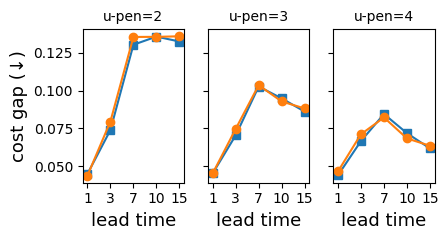

In [4]:
if "marginal_gap" in PAPER_FIGURES[task_name]:
    fig = figures.plot_marginal(metrics, "gap", "absolute", 
                                SELECT[task_name], **FIG_KW[task_name].get("marginal_gap", {}))
    fig.savefig(f"{fig_dir}/marginal_gap.pdf", bbox_inches="tight")

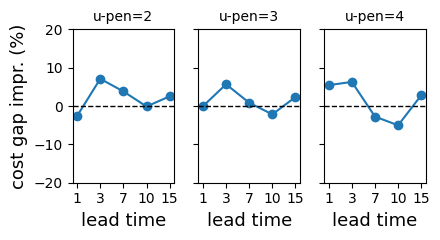

In [5]:
if "marginal_gap_relative" in PAPER_FIGURES[task_name]:
    fig = figures.plot_marginal(metrics, "gap", "relative", 
                                SELECT[task_name], **FIG_KW[task_name].get("marginal_gap_relative", {}))
    fig.savefig(f"{fig_dir}/marginal_gap_relative.pdf", bbox_inches="tight")

### Cost

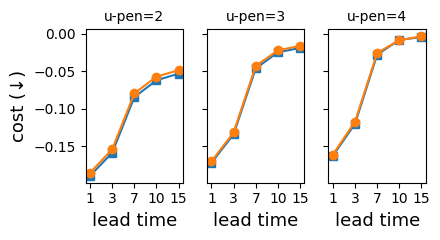

In [6]:
if "marginal_cost" in PAPER_FIGURES[task_name]:
    fig = figures.plot_marginal(metrics, "obs_cost", "absolute",
                                SELECT[task_name], **FIG_KW[task_name].get("marginal_cost", {}))
    fig.savefig(f"{fig_dir}/marginal_cost.pdf", bbox_inches="tight")

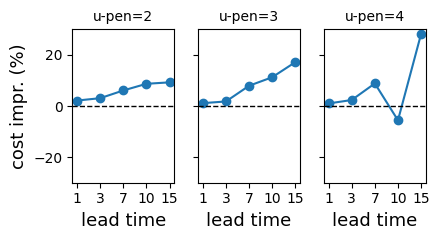

In [7]:
if "marginal_cost_relative" in PAPER_FIGURES[task_name]:
    fig = figures.plot_marginal(metrics, "obs_cost", "relative", 
                                SELECT[task_name], **FIG_KW[task_name].get("marginal_cost_relative", {}))
    fig.savefig(f"{fig_dir}/marginal_cost_relative.pdf", bbox_inches="tight")

## Heatmaps

### Cost gap

In [8]:
if "heatmap_gap" in PAPER_FIGURES[task_name]:
    fig = figures.plot_heatmap(metrics, "gap", **FIG_KW[task_name].get("heatmap_gap", {}))
    fig.savefig(f"{fig_dir}/heatmap_gap.pdf", bbox_inches="tight")


### Cost

In [9]:
if "heatmap_cost" in PAPER_FIGURES[task_name]:
    fig = figures.plot_heatmap(metrics, "obs_cost", **FIG_KW[task_name].get("heatmap_cost", {}))
    fig.savefig(f"{fig_dir}/heatmap_cost.pdf", bbox_inches="tight")


## Maps

### Cost gap

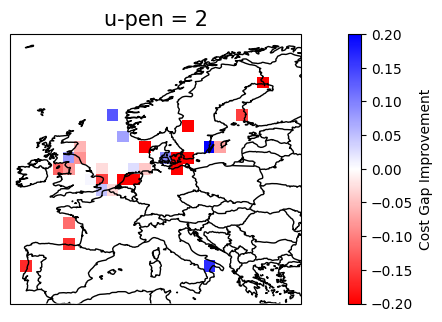

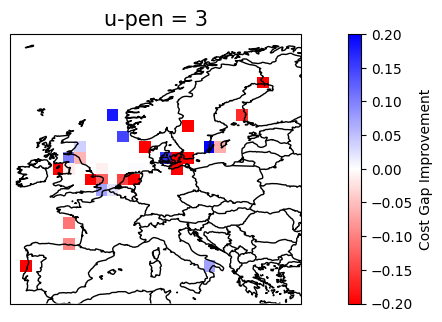

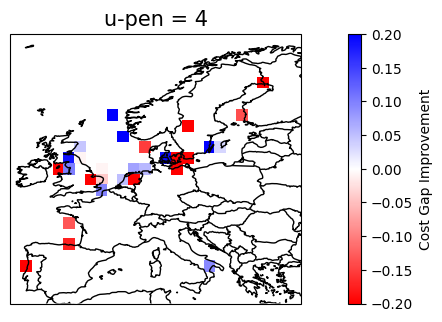

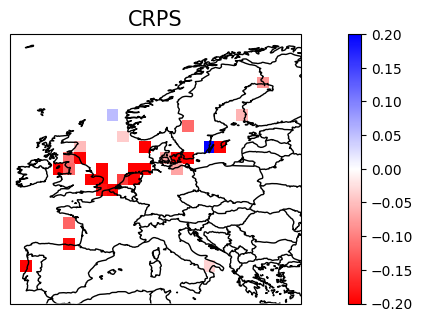

In [10]:
if "map_gap" in PAPER_FIGURES[task_name]:
    kw = FIG_KW[task_name].get("map_gap", {})                     # lead / vmin / vmax, shared with CRPS
    for sel in MAP_SELECT[task_name]:
        fig = figures.plot_map(metrics, "gap", select=sel, **kw)
        fig.savefig(f"{fig_dir}/map_gap_{'_'.join(f'{k}{v}' for k, v in sel.items())}.pdf", bbox_inches="tight")

    # CRPS map, always alongside the gap maps (same lead and colorbar limits)
    fig = figures.plot_map(metrics, "crps", title="CRPS", cbar=dict(fraction=0.046, pad=0.04), **kw)
    fig.savefig(f"{fig_dir}/map_crps.pdf", bbox_inches="tight")



### Cost

Note (wind power): the colours of this map are inverted in the appendix (sign error in the original plotting code for negative costs); this version is correct. No other figure is affected.

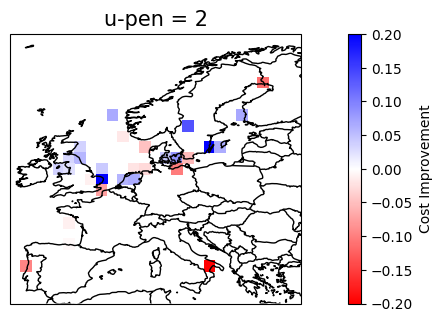

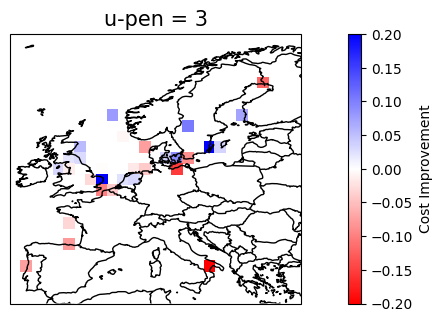

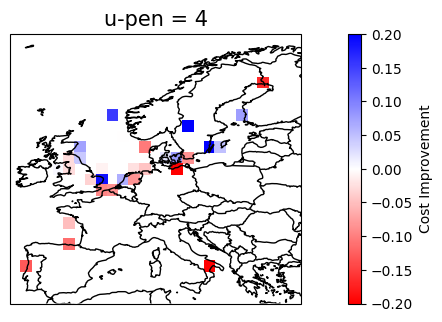

In [11]:
if "map_cost" in PAPER_FIGURES[task_name]:
    kw = FIG_KW[task_name].get("map_cost", {})                     # same lead / vmin / vmax as the gap maps
    for sel in MAP_SELECT[task_name]:
        fig = figures.plot_map(metrics, "obs_cost", select=sel, **kw)
        fig.savefig(f"{fig_dir}/map_cost_{'_'.join(f'{k}{v}' for k, v in sel.items())}.pdf", bbox_inches="tight")


## Standard metrics

### CRPS

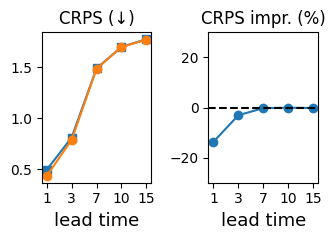

In [12]:
if "crps" in PAPER_FIGURES[task_name]:
    fig = figures.plot_crps(metrics, **FIG_KW[task_name].get("crps", {}))
    fig.savefig(f"{fig_dir}/crps.pdf", bbox_inches="tight")


### PIT histograms

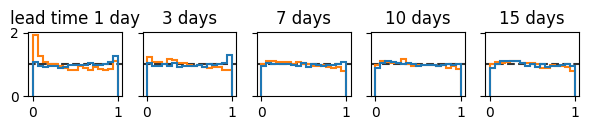

In [13]:
if "pit" in PAPER_FIGURES[task_name]:
    fig = figures.plot_pit(metrics)
    fig.savefig(f"{fig_dir}/pit.pdf", bbox_inches="tight")


### Spread-Skill Ratio

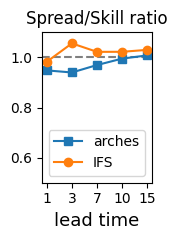

In [14]:
if "ssr" in PAPER_FIGURES[task_name]:
    fig = figures.plot_ssr(metrics, **FIG_KW[task_name].get("ssr", {}))
    fig.savefig(f"{fig_dir}/ssr.pdf", bbox_inches="tight")
